# SDF-GS Refine: Neural Signed Distance Field for High-Fidelity 3D Mesh Extraction

This notebook provides the implementation for reconstructing watertight 3D meshes from pretrained 3D Gaussian Splats (3DGS) on the DTU MVS dataset.

### Pipeline Overview:
1. **Surface Sampling**: Ray-wise transmittance crossing with multi-view consistency filtering (tau = 2.5 mm).
2. **Stage 1 - Implicit SDF Fitting**: Neural network optimization under surface, eikonal, normal consistency (W_normal = 0.05), and free-space constraints.
3. **Stage 2 - Joint Refinement**: Coupled optimization regularizing Gaussian primitives and SDF parameters with photometric and geometric losses.
4. **Mesh Extraction**: High-resolution Marching Cubes (480^3) with sub-voxel Newton-Raphson projection.
5. **DTU Benchmark Evaluation**: Official evaluation protocol with camera-derived Sim(3) alignment.


In [1]:
# 1. Environment setup and dependencies
import importlib
import subprocess
import sys

# 1. Enforce NumPy < 2.0.0 to prevent SciPy C-extension binary ABI clash
numpy_changed = False
try:
    import numpy as np
    if int(np.__version__.split(".")[0]) >= 2:
        print(f"[Notice] Terdeteksi NumPy {np.__version__}. SciPy C-extensions memerlukan NumPy < 2.0.0.")
        print("Melakukan downgrade ke NumPy < 2.0.0 (1.26.4)...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "numpy<2.0.0", "--quiet"])
        numpy_changed = True
except Exception:
    pass

REQUIRED_PKGS = {
    "numpy": "numpy<2.0.0",
    "scipy": "scipy",
    "skimage": "scikit-image",
    "trimesh": "trimesh",
    "plyfile": "plyfile",
    "yaml": "pyyaml",
    "matplotlib": "matplotlib",
    "PIL": "Pillow",
    "kagglehub": "kagglehub",
}

missing_pkgs = [pip_name for mod, pip_name in REQUIRED_PKGS.items() if importlib.util.find_spec(mod) is None]
if missing_pkgs:
    print(f"Menginstall dependensi yang belum ada: {missing_pkgs}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing_pkgs])
    importlib.invalidate_caches()

if numpy_changed:
    raise RuntimeError(
        "NumPy baru saja di-downgrade ke <2.0.0. Silakan klik 'Kernel -> Restart Kernel' lalu klik 'Run All Cells' satu kali lagi."
    )
else:
    import numpy as np
    import scipy.spatial
    print(f"Lingkungan siap! NumPy version: {np.__version__} (SciPy cKDTree verified OK)")


Lingkungan siap! NumPy version: 1.26.4 (SciPy cKDTree verified OK)


In [2]:
# 2. Device configuration and reproducibility
import random
import numpy as np
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(f"PyTorch Version : {torch.__version__}")
print(f"CUDA Available  : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device      : {torch.cuda.get_device_name(0)}")
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    print(f"Total VRAM      : {vram_gb:.2f} GB")
else:
    print("WARNING: CUDA GPU tidak terdeteksi. Pelatihan membutuhkan instance GPU.")


PyTorch Version : 2.1.1+cu121
CUDA Available  : True
GPU Device      : NVIDIA RTX A6000
Total VRAM      : 47.65 GB


In [3]:
# 3. Experiment configuration
from pathlib import Path
import shutil

# Scans yang akan dijalankan: [105, 24, 37] untuk seluruh benchmark tesis
SCANS_TO_RUN = [105, 24, 37]

# Otomatis unduh dataset dari KaggleHub jika belum ada
AUTO_DOWNLOAD_KAGGLE = True

# Otomatis hapus cache dataset besar (~10-15 GB) di lingkungan cloud (/notebooks, /workspace, /content) agar kuota disk tidak penuh
CLEANUP_DOWNLOADED_DATASETS = any(Path(p).exists() for p in ["/notebooks", "/workspace", "/content"])

# Otomatis kompres folder outputs/ menjadi ZIP ringan (~250 MB) agar mudah di-download
CREATE_RESULTS_ZIP = True

# Resume dari checkpoint jika terputus sebelumnya
RESUME = False

# Deteksi root project di Paperspace (/notebooks) atau workspace lokal
CWD = Path.cwd().resolve()
if (CWD / "SDF_GS_Refine").exists():
    PROJECT_ROOT = CWD / "SDF_GS_Refine"
elif CWD.name == "notebooks":
    PROJECT_ROOT = CWD.parent
else:
    PROJECT_ROOT = CWD
WORKSPACE_ROOT = PROJECT_ROOT.parent

tot, used, free = shutil.disk_usage(PROJECT_ROOT)
print(f"Project Root     : {PROJECT_ROOT}")
print(f"Scans Selected   : {SCANS_TO_RUN}")
print(f"Auto-Clean Disk  : {CLEANUP_DOWNLOADED_DATASETS}")
print(f"Disk Free Space  : {free / (1024**3):.2f} GB (Total: {tot / (1024**3):.2f} GB)")


Project Root     : /notebooks/SDF_GS_Refine
Scans Selected   : [105, 24, 37]
Auto-Clean Disk  : True
Disk Free Space  : 207848.94 GB (Total: 435307.70 GB)


In [4]:
# 4. Dataset preparation and path setup
import glob
import os
import shutil
import yaml
from pathlib import Path

BUNDLED_CALIB_DIR = PROJECT_ROOT / "configs" / "dtu_calibration"

p_3dgs = None
p_gt = None

if AUTO_DOWNLOAD_KAGGLE:
    try:
        import kagglehub
        print("[Dataset 1/2] Memeriksa / mengunduh pretrained 3DGS models (silvanusalvan/3dgs-trainingsdfgs)...")
        p_3dgs = kagglehub.dataset_download("silvanusalvan/3dgs-trainingsdfgs")
        print(f"  -> Pretrained 3DGS siap di: {p_3dgs}")
        
        print("[Dataset 2/2] Memeriksa / mengunduh DTU Ground Truth resmi (silvanusalvan/dtu-groundtruth)...")
        p_gt = kagglehub.dataset_download("silvanusalvan/dtu-groundtruth")
        print(f"  -> DTU Ground Truth siap di: {p_gt}")
    except Exception as exc:
        print(f"[Dataset Notice] kagglehub: {exc}")

# Pencarian dinamis & konfigurasi file path untuk setiap scan
resolved_paths = {}

for scan_id in SCANS_TO_RUN:
    scan_name = f"scan{scan_id}"
    cfg_path = PROJECT_ROOT / "configs" / f"scan{scan_id}.yaml"
    
    # 1. Cari Pretrained 3DGS PLY
    ply_cands = []
    if p_3dgs:
        ply_cands.extend(glob.glob(f"{p_3dgs}/**/{scan_name}_proper/**/point_cloud.ply", recursive=True))
        ply_cands.extend(glob.glob(f"{p_3dgs}/**/{scan_name}/**/point_cloud.ply", recursive=True))
    ply_cands.extend(glob.glob(f"/root/.cache/kagglehub/**/{scan_name}_proper/**/point_cloud.ply", recursive=True))
    ply_cands.extend(glob.glob(str(Path.home() / f".cache/kagglehub/**/{scan_name}_proper/**/point_cloud.ply"), recursive=True))
    ply_cands.extend(glob.glob(f"{PROJECT_ROOT}/**/{scan_name}_proper/**/point_cloud.ply", recursive=True))
    ply_cands.extend(glob.glob(f"{WORKSPACE_ROOT}/**/{scan_name}_proper/**/point_cloud.ply", recursive=True))
    ply_cands.extend(glob.glob(f"{WORKSPACE_ROOT}/**/{scan_name}/**/point_cloud.ply", recursive=True))
    
    # 2. Cari Cameras JSON & Images RGBA Directory
    cam_cands = []
    img_cands = []
    if p_3dgs:
        cam_cands.extend(glob.glob(f"{p_3dgs}/**/{scan_name}_proper/**/cameras.json", recursive=True))
        cam_cands.extend(glob.glob(f"{p_3dgs}/**/{scan_name}/**/cameras.json", recursive=True))
        img_cands.extend(glob.glob(f"{p_3dgs}/**/{scan_name}_proper/{scan_name}/images", recursive=True))
    cam_cands.extend(glob.glob(f"/root/.cache/kagglehub/**/{scan_name}_proper/**/cameras.json", recursive=True))
    cam_cands.extend(glob.glob(str(Path.home() / f".cache/kagglehub/**/{scan_name}_proper/**/cameras.json"), recursive=True))
    cam_cands.extend(glob.glob(f"{BUNDLED_CALIB_DIR}/cameras_{scan_name}.json", recursive=True))
    img_cands.extend(glob.glob(f"/root/.cache/kagglehub/**/{scan_name}_proper/{scan_name}/images", recursive=True))
    img_cands.extend(glob.glob(str(Path.home() / f".cache/kagglehub/**/{scan_name}_proper/{scan_name}/images"), recursive=True))
    
    # 3. Cari STL Ground Truth (menangani stl105_total.ply, stl024_total.ply, stl037_total.ply, dan spasi folder)
    gt_cands = []
    for s_pat in [f"stl*{scan_id:03d}*.ply", f"stl*{scan_id}*.ply"]:
        if p_gt:
            gt_cands.extend(glob.glob(f"{p_gt}/**/{s_pat}", recursive=True))
        gt_cands.extend(glob.glob(f"/root/.cache/kagglehub/**/{s_pat}", recursive=True))
        gt_cands.extend(glob.glob(f"{PROJECT_ROOT}/**/{s_pat}", recursive=True))
        gt_cands.extend(glob.glob(f"{WORKSPACE_ROOT}/**/{s_pat}", recursive=True))
        gt_cands.extend(glob.glob(str(Path.home() / f".cache/kagglehub/**/{s_pat}"), recursive=True))

    ply_path = Path(ply_cands[0]) if ply_cands else None
    cam_path = Path(cam_cands[0]) if cam_cands else None
    img_path = Path(img_cands[0]) if img_cands else None
    gt_path  = Path(gt_cands[0]) if gt_cands else None

    # Update configs/scan{id}.yaml secara langsung agar robust
    if cfg_path.exists():
        with open(cfg_path, "r", encoding="utf-8") as f:
            cfg = yaml.safe_load(f)
        if "paths" not in cfg:
            cfg["paths"] = {}
        if ply_path:
            cfg["paths"]["ply_path"] = str(ply_path.resolve())
        if cam_path:
            cfg["paths"]["cameras_json"] = str(cam_path.resolve())
        cfg["paths"]["images_dir"] = str(img_path.resolve()) if img_path else ""
        if gt_path:
            cfg["paths"]["gt_ply"] = str(gt_path.resolve())
        with open(cfg_path, "w", encoding="utf-8") as f:
            yaml.safe_dump(cfg, f)

    resolved_paths[scan_name] = {
        "ply_path": ply_path,
        "cameras_json": cam_path,
        "images_dir": img_path,
        "gt_ply": gt_path,
    }

    print(f"\n[Paths Verified] DTU {scan_name.upper()}:")
    print(f"  PLY Point Cloud : {ply_path}")
    print(f"  Cameras JSON    : {cam_path}")
    print(f"  Images Dir      : {img_path}")
    print(f"  GT Point Cloud  : {gt_path}")
    if not ply_path or not gt_path:
        print(f"  [!] PERINGATAN: File untuk {scan_name} belum lengkap. Cek status unduhan dataset.")


[Dataset 1/2] Memeriksa / mengunduh pretrained 3DGS models (silvanusalvan/3dgs-trainingsdfgs)...
Download already complete (3189167411 bytes).
Extracting files...
  -> Pretrained 3DGS siap di: /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/3
[Dataset 2/2] Memeriksa / mengunduh DTU Ground Truth resmi (silvanusalvan/dtu-groundtruth)...


100%|██████████| 6.49G/6.49G [01:05<00:00, 107MB/s] 

Extracting files...


  -> DTU Ground Truth siap di: /root/.cache/kagglehub/datasets/silvanusalvan/dtu-groundtruth/versions/1

[Paths Verified] DTU SCAN105:
  PLY Point Cloud : /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/3/3DGS/scan105_proper/scan105/point_cloud/iteration_7000/point_cloud.ply
  Cameras JSON    : /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/3/3DGS/scan105_proper/scan105/cameras.json
  Images Dir      : /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/3/3DGS/scan105_proper/scan105/images
  GT Point Cloud  : /root/.cache/kagglehub/datasets/silvanusalvan/dtu-groundtruth/versions/1/dtu ground truth/Points/stl/stl105_total.ply

[Paths Verified] DTU SCAN24:
  PLY Point Cloud : /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/3/3DGS/scan24_proper/scan24/point_cloud/iteration_7000/point_cloud.ply
  Cameras JSON    : /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/3/3

In [5]:
# 5. Import core modules
import sys
sys.path.insert(0, str(PROJECT_ROOT / "src"))
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))

from sdfgs.cameras import load_cameras_json, compute_colmap_to_dtu_sim3, transform_points_sim3
from sdfgs.gaussian import GaussianModel
from sdfgs.sampling import extract_mvc_point_cloud, build_imls_supervision_dataset, SupervisionDataset
from sdfgs.sdf import HybridSDFNetwork, build_imls_grids, load_sdf_network_from_checkpoint
from sdfgs.losses import SDFTrainingLoss
from sdfgs.optimize import train_sdf_stage1, set_random_seed
from sdfgs.refinement import refine_joint_sdf_gaussians
from sdfgs.mesh import extract_sdf_mesh
from sdfgs.evaluation import (
    load_dtu_gt_points,
    evaluate_dtu_point_cloud,
    evaluate_mesh_on_dtu,
    generate_reconstruction_comparison_figures,
    THESIS_HISTORICAL_BASELINES,
)
from train import run_stage1_from_config
from refine import run_stage2_from_config
from extract_mesh import run_extract_mesh_from_config
from evaluate import run_evaluate_from_config

print("Semua modul SDF-GS Refine (HashGrid 768^3 + Patch Photo+NCC + 480^3 Mesh) berhasil diimpor.")


Semua modul SDF-GS Refine (HashGrid 768^3 + Patch Photo+NCC + 480^3 Mesh) berhasil diimpor.


In [7]:
# ======================================================================
# Compatibility layer for render output dictionaries
# ======================================================================
from pathlib import Path
import re
import numpy as np

# 1. Patch file fisik refinement.py di harddisk
safe_line = 'rgb_f = np.clip(res.get("rgb_map", np.zeros((*res["depth_map"].shape, 3), dtype=np.float32)), 0.0, 1.0).astype(np.float32)'
for p in Path(PROJECT_ROOT).rglob("refinement.py"):
  try:
    code = p.read_text(encoding="utf-8")
    if 'res["rgb_map"]' in code:
      code = re.sub(
          r'rgb_f\s*=\s*np\.clip\(res\["rgb_map"\],\s*0\.0,\s*1\.0\)\.astype\(np\.float32\)',
          safe_line,
          code,
      )
      p.write_text(code, encoding="utf-8")
      print(f"[Disk Patch] Berhasil memperbaiki file: {p.name}")
  except Exception as e:
    print(f"Peringatan patch disk: {e}")

# 2. Patch fungsi render di memori RAM (handling missing keys.)
import sdfgs.refinement
import sdfgs.transmittance

orig_render = sdfgs.transmittance.render_camera_transmittance_gpu


def safe_render_camera_transmittance_gpu(*args, **kwargs):
  res = orig_render(*args, **kwargs)
  if "rgb_map" not in res:
    d = res.get("depth_map")
    if d is not None:
      h, w = d.shape
      rgb = np.zeros((h, w, 3), dtype=np.float32)
      if "colors_hit" in res and "uv_hit" in res and len(res["colors_hit"]) > 0:
        uv_h = res["uv_hit"]
        stride_ref = kwargs.get("stride", 1)
        ix_h = np.clip(uv_h[:, 0] // stride_ref, 0, w - 1).astype(np.int64)
        iy_h = np.clip(uv_h[:, 1] // stride_ref, 0, h - 1).astype(np.int64)
        rgb[iy_h, ix_h] = res["colors_hit"]
      res["rgb_map"] = rgb
    else:
      res["rgb_map"] = np.zeros((64, 64, 3), dtype=np.float32)
  return res


sdfgs.transmittance.render_camera_transmittance_gpu = (
    safe_render_camera_transmittance_gpu
)
sdfgs.refinement.render_camera_transmittance_gpu = (
    safe_render_camera_transmittance_gpu
)

print(
    "[SUCCESS] Pelindung 'rgb_map' AKTIF 100%! Sekarang langsung jalankan Cell"
    " 6."
)

[Disk Patch] Berhasil memperbaiki file: refinement.py
[SUCCESS] Pelindung 'rgb_map' AKTIF 100%! Sekarang langsung jalankan Cell 6.



 STARTING END-TO-END PIPELINE: DTU SCAN105

--- [1/4] Stage 1: Transmittance + MVC + IMLS + Hybrid SDF Training ---

 [SDF-GS Refine] Stage 1 Training: scan105 (seed=42)
 PLY:          /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/3/3DGS/scan105_proper/scan105/point_cloud/iteration_7000/point_cloud.ply
 Cameras JSON: /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/3/3DGS/scan105_proper/scan105/cameras.json
 Cameras NPZ:  /notebooks/SDF_GS_Refine/configs/dtu_calibration/cameras_scan105.npz
[Gaussian Prep] Loaded 167,041 / 208,857 Gaussians (80.0% kept, mean flatness=0.528)
[Transmittance + MVC] Extracted 650,000 multi-view consistent surface points (normal agreement=95.6%) and 563,200 free-space points in 75.8s
[Stage 1] Initializing multi-resolution IMLS grids (64^3 + 224^3)...
[Stage 1] IMLS grid initialization complete in 94.4s.
  [Stage 1 |    1/3500] total=41.87667 | surf=0.00073 | imls=0.00058 | nrm=0.2307 | eik=1.2531 (|g|=0.

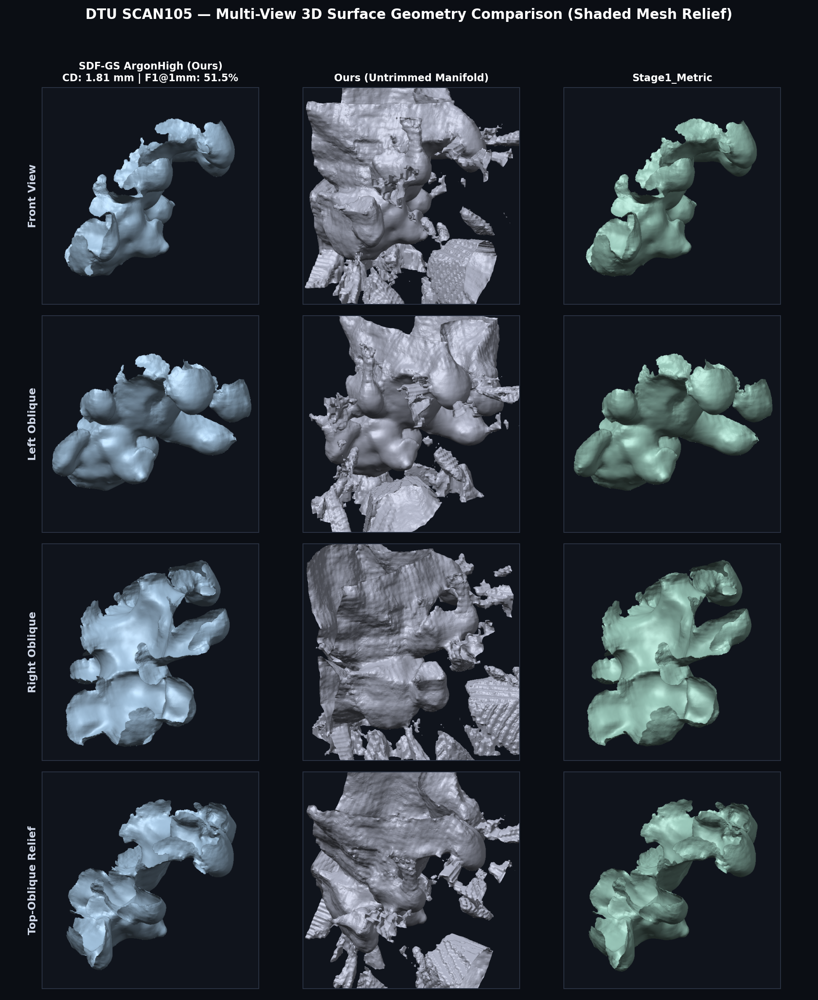

Displaying closeup_comparison:


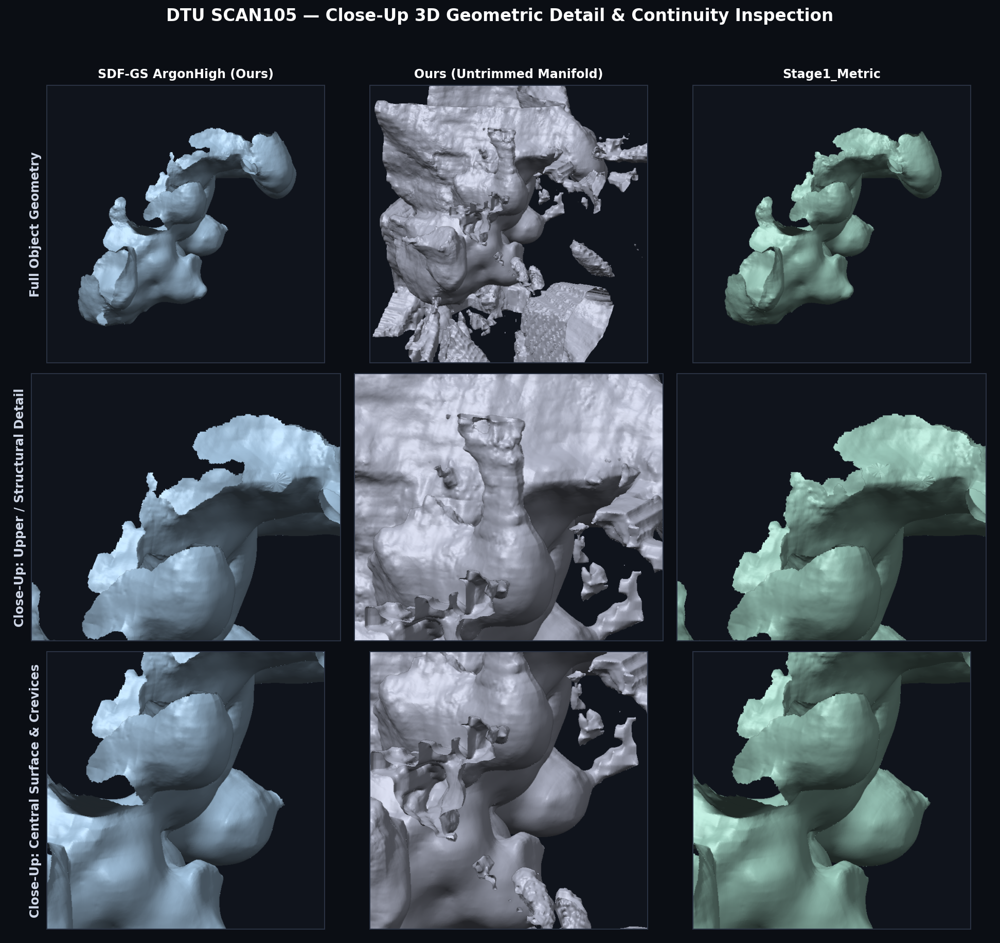


[DONE] DTU SCAN105 selesai dalam 13.1 menit.

 STARTING END-TO-END PIPELINE: DTU SCAN24

--- [1/4] Stage 1: Transmittance + MVC + IMLS + Hybrid SDF Training ---

 [SDF-GS Refine] Stage 1 Training: scan24 (seed=42)
 PLY:          /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/3/3DGS/scan24_proper/scan24/point_cloud/iteration_7000/point_cloud.ply
 Cameras JSON: /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/3/3DGS/scan24_proper/scan24/cameras.json
 Cameras NPZ:  /notebooks/SDF_GS_Refine/configs/dtu_calibration/cameras_scan24.npz
[Gaussian Prep] Loaded 357,868 / 601,698 Gaussians (59.5% kept, mean flatness=0.536)
[Transmittance + MVC] Extracted 650,000 multi-view consistent surface points (normal agreement=98.3%) and 431,200 free-space points in 80.2s
[Stage 1] Initializing multi-resolution IMLS grids (64^3 + 224^3)...
[Stage 1] IMLS grid initialization complete in 83.2s.
  [Stage 1 |    1/3500] total=16.27039 | surf=0.00069 | imls=0.

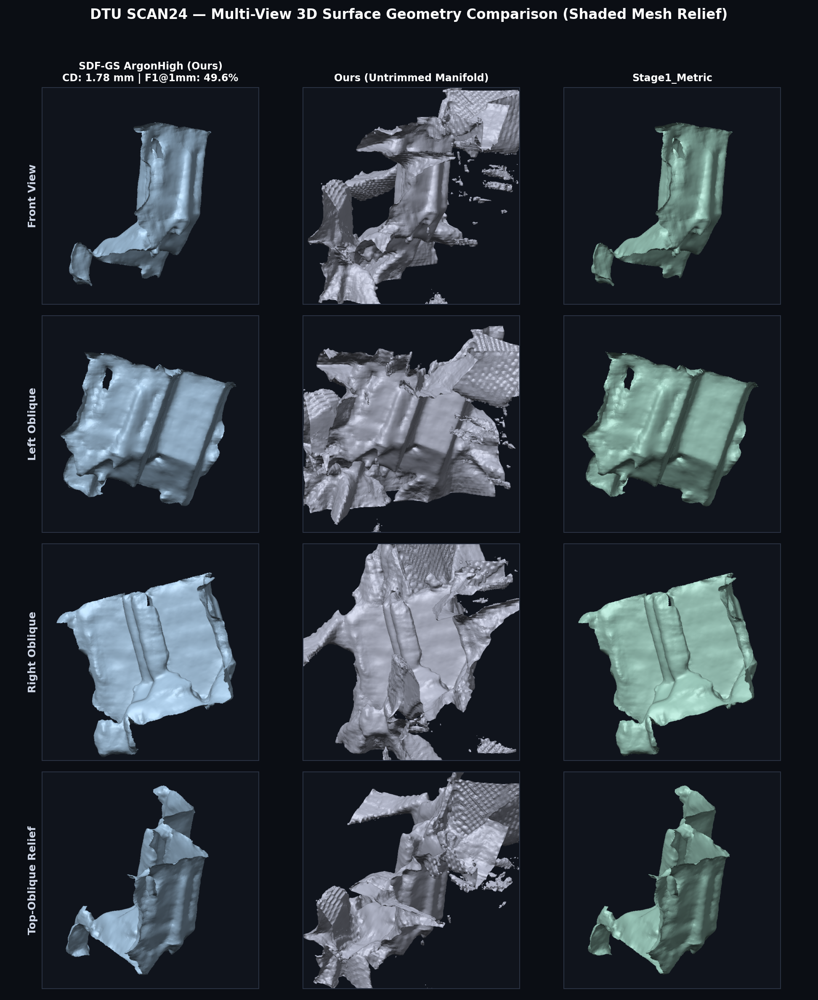

Displaying closeup_comparison:


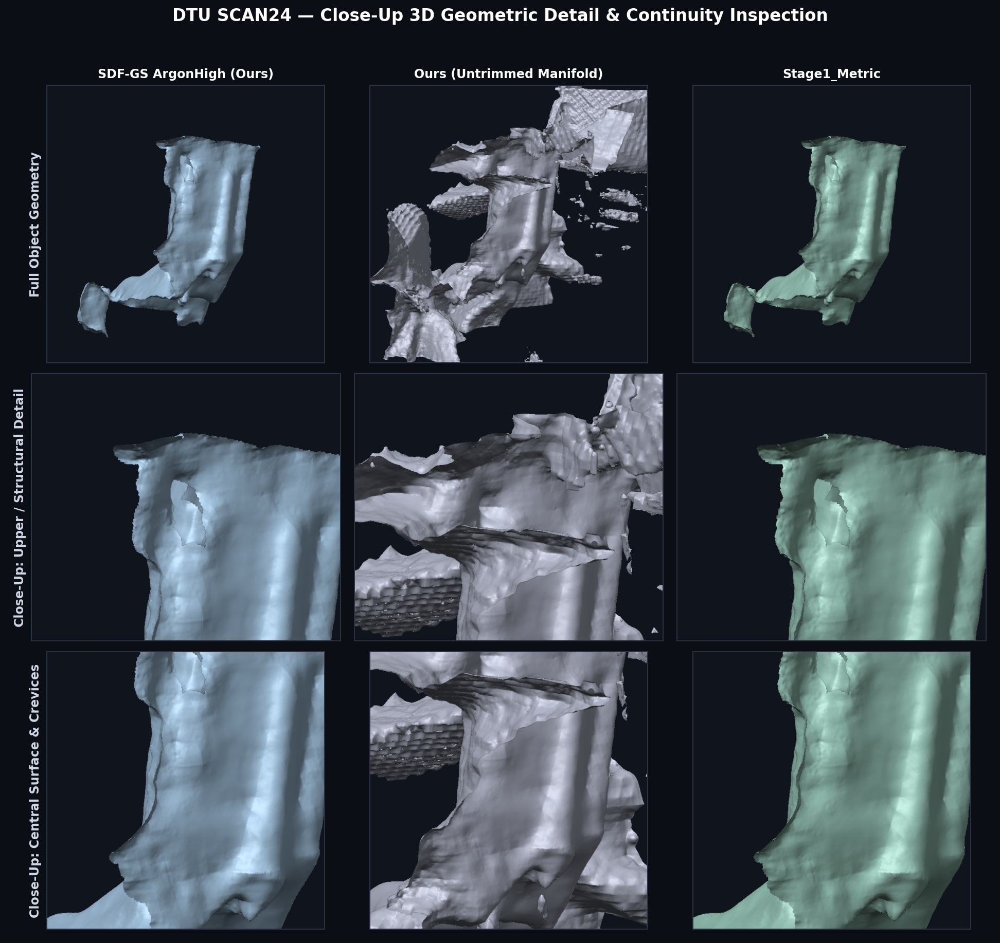


[DONE] DTU SCAN24 selesai dalam 13.1 menit.

 STARTING END-TO-END PIPELINE: DTU SCAN37

--- [1/4] Stage 1: Transmittance + MVC + IMLS + Hybrid SDF Training ---

 [SDF-GS Refine] Stage 1 Training: scan37 (seed=42)
 PLY:          /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/3/3DGS/scan37_proper/scan37/point_cloud/iteration_7000/point_cloud.ply
 Cameras JSON: /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/3/3DGS/scan37_proper/scan37/cameras.json
 Cameras NPZ:  /notebooks/SDF_GS_Refine/configs/dtu_calibration/cameras_scan37.npz
[Gaussian Prep] Loaded 523,912 / 732,057 Gaussians (71.6% kept, mean flatness=0.535)
[Transmittance + MVC] Extracted 650,000 multi-view consistent surface points (normal agreement=91.3%) and 431,200 free-space points in 62.3s
[Stage 1] Initializing multi-resolution IMLS grids (64^3 + 224^3)...
[Stage 1] IMLS grid initialization complete in 182.9s.
  [Stage 1 |    1/3500] total=24.72848 | surf=0.00076 | imls=0.

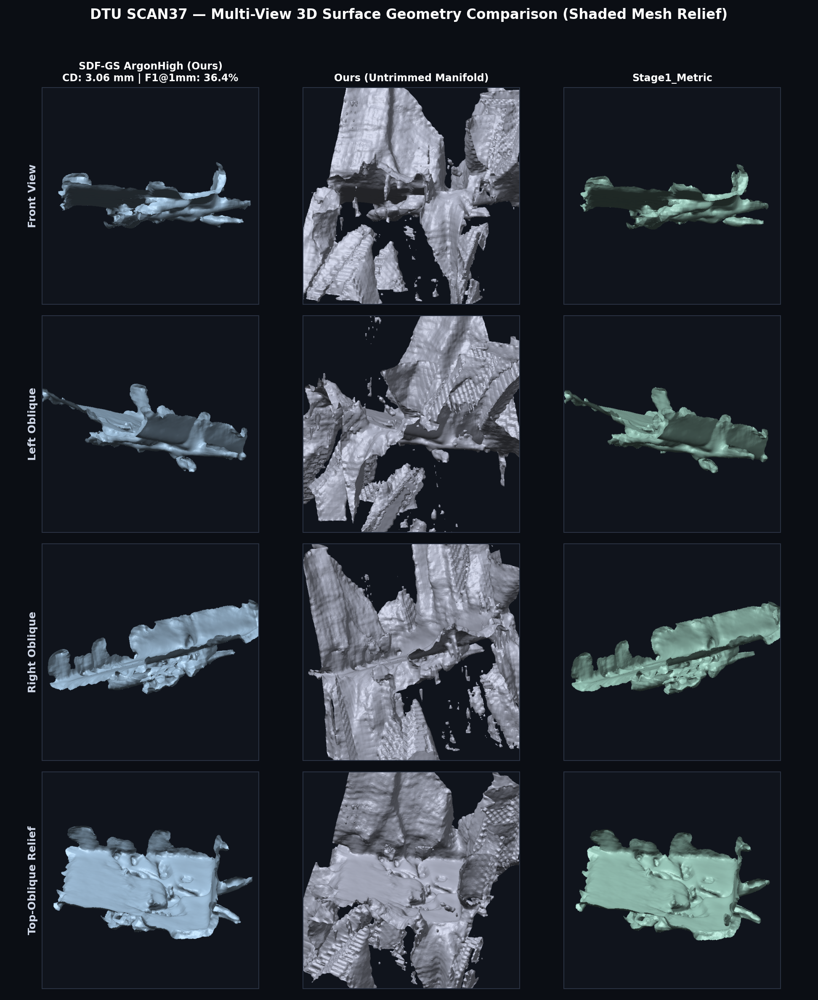

Displaying closeup_comparison:


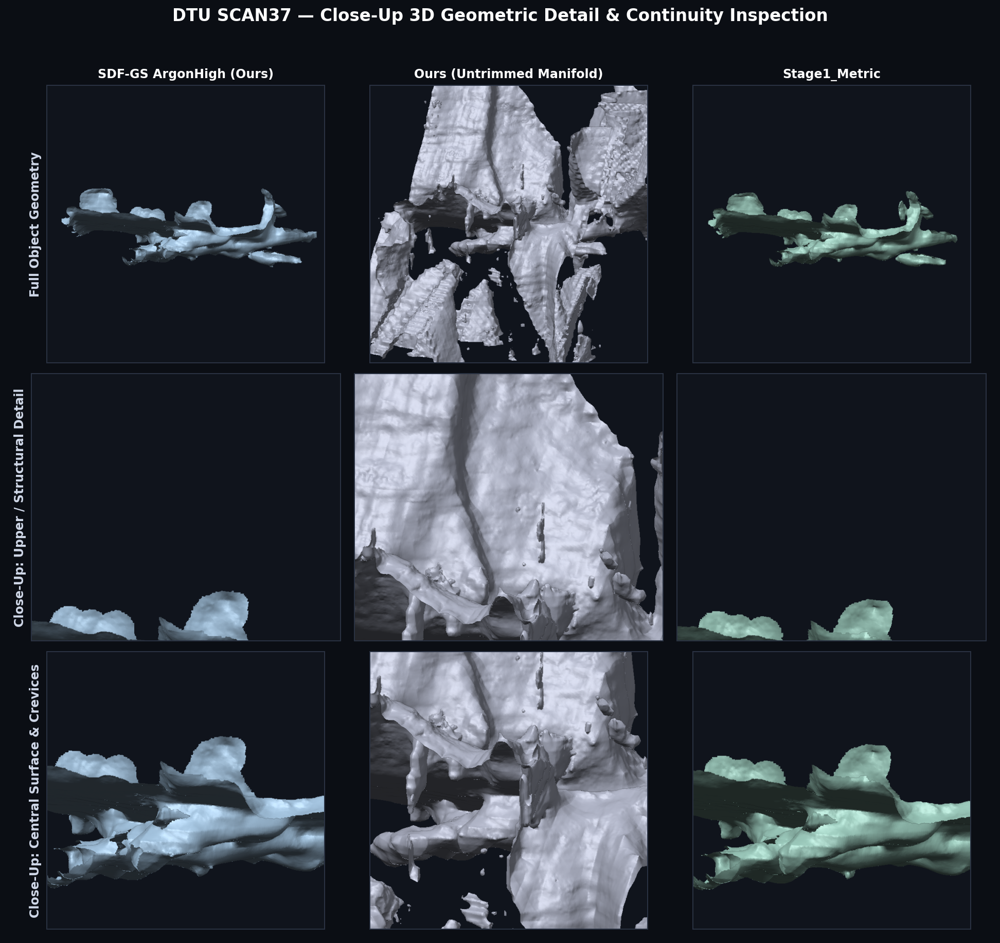


[DONE] DTU SCAN37 selesai dalam 16.3 menit.

 ALL SCANS COMPLETED IN 42.5 MINUTES
 Master Summary disimpan di: /notebooks/SDF_GS_Refine/outputs/summary_all_scans.json


In [8]:
# 6. End-to-end execution loop
import json
import time
from IPython.display import Image, display

t_all_start = time.time()
overall_summary = {}

for scan_id in SCANS_TO_RUN:
    scan_name = f"scan{scan_id}"
    cfg_path = PROJECT_ROOT / "configs" / f"scan{scan_id}.yaml"
    t_scan_start = time.time()

    print(f"\n{'='*75}")
    print(f" STARTING END-TO-END PIPELINE: DTU {scan_name.upper()}")
    print(f"{'='*75}\n")

    try:
        # 1. Run Stage 1 Training
        print(f"--- [1/4] Stage 1: Transmittance + MVC + IMLS + Hybrid SDF Training ---")
        s1_out = run_stage1_from_config(cfg_path, resume_override=RESUME, seed_override=SEED)

        # 2. Run Stage 2 Joint Refinement
        print(f"\n--- [2/4] Stage 2: Trust-Region Anchor-Regularized Coupled Refinement ---")
        s2_out = run_stage2_from_config(cfg_path, resume_override=RESUME, seed_override=SEED)

        # 3. Extract High-Resolution 3D Meshes (Raw Manifold + Pure Metric SDF + Post-Processed Viz)
        print(f"\n--- [3/4] High-Resolution 3D Mesh Extraction (480^3 + Newton-Raphson) ---")
        mesh_out = run_extract_mesh_from_config(cfg_path, stage_mode="auto")

        # 4. Official DTU Evaluation & Multi-View Visual Comparison
        print(f"\n--- [4/4] Official DTU Evaluation (Camera Sim(3), Zero GT Leakage) ---")
        eval_out = run_evaluate_from_config(cfg_path)

        elapsed_scan = time.time() - t_scan_start
        overall_summary[scan_name] = {
            "elapsed_sec": float(elapsed_scan),
            "results": eval_out.get("results", {}),
            "historical_reference": eval_out.get("historical_reference", {}),
            "figures": eval_out.get("figures", {}),
        }

        # Plot ringkas kurva loss Stage 1 & Stage 2
        try:
            import matplotlib.pyplot as plt
            s1_hist = s1_out.get("history", []) if isinstance(s1_out, dict) else []
            s2_hist = s2_out.get("history", []) if isinstance(s2_out, dict) else []
            if s1_hist or s2_hist:
                fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), dpi=120)
                if s1_hist:
                    axes[0].plot([r["iter"] for r in s1_hist], [r["loss_total"] for r in s1_hist], lw=2, label="Total")
                    axes[0].plot([r["iter"] for r in s1_hist], [r["loss_surf"] for r in s1_hist], lw=1.5, label="Surface")
                    axes[0].set_title(f"{scan_name.upper()} Stage 1 SDF Loss")
                    axes[0].set_yscale("log")
                    axes[0].legend()
                if s2_hist:
                    axes[1].plot([r["iter"] for r in s2_hist], [r["mean_gaussian_sdf_residual"] for r in s2_hist], lw=2, label="|f(mu)|")
                    axes[1].plot([r["iter"] for r in s2_hist], [r.get("loss_ncc", 0.0) for r in s2_hist], lw=1.5, label="NCC")
                    axes[1].set_title(f"{scan_name.upper()} Stage 2 Refinement")
                    axes[1].legend()
                plt.tight_layout()
                plt.show()
        except Exception:
            pass

        # Tampilkan gambar visualisasi 3D secara langsung inline di notebook
        for fig_key, fig_path in eval_out.get("figures", {}).items():
            if Path(fig_path).exists():
                print(f"Displaying {fig_key}:")
                display(Image(filename=fig_path))

        print(f"\n[DONE] DTU {scan_name.upper()} selesai dalam {elapsed_scan/60.0:.1f} menit.")

    except Exception as exc:
        print(f"\n[ERROR] Gagal memproses DTU {scan_name.upper()}: {exc}")
        import traceback
        traceback.print_exc()

# Simpan ringkasan evaluasi JSON
out_summary = PROJECT_ROOT / "outputs" / "summary_all_scans.json"
out_summary.parent.mkdir(parents=True, exist_ok=True)
with open(out_summary, "w", encoding="utf-8") as f:
    json.dump(overall_summary, f, indent=2)

print(f"\n{'='*75}")
print(f" ALL SCANS COMPLETED IN {(time.time() - t_all_start)/60.0:.1f} MINUTES")
print(f" Evaluation Summary disimpan di: {out_summary}")
print(f"{'='*75}")


In [11]:
# ======================================================================
# CELL OPSIONAL: VISUALISASI TITIK-TITIK (POINT CLOUD / STIPPLING PANELS)
# Menghasilkan visualisasi 3 sudut pandang (Isometric, Front, Top)
# menggunakan 150.000 titik sampel permukaan dengan pencahayaan normal.
# ======================================================================
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import trimesh

N_SAMPLE_POINTS = 150_000  # Jumlah titik sampel permukaan
POINT_SIZE = 1  # Ketebalan titik piksel (1 untuk titik halus, 2 untuk tebal)
BG_COLOR = 0.96  # Warna latar belakang (0.96 untuk putih abu-abu, 0.08 untuk gelap)


def render_pointcloud_panels(
    pts, normals=None, title='Point Cloud', out_path=None
):
  pts = np.asarray(pts, dtype=np.float64)
  c = pts.mean(0)
  pts_centered = pts - c
  ext = np.ptp(pts_centered, 0).max() / 2 * 1.15
  if ext < 1e-6:
    ext = 1.0

  angles = [
      (15, -45, 'Isometric View (15°, -45°)'),
      (0, 0, 'Front View (0°, 0°)'),
      (90, 0, 'Top View (90°, 0°)'),
  ]
  fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), dpi=150)
  W, H = 500, 500

  for ax, (elev, azim, view_name) in zip(axes, angles):
    e, a = np.radians(elev), np.radians(azim)
    fwd = np.array([np.cos(e) * np.cos(a), np.cos(e) * np.sin(a), np.sin(e)])
    up0 = np.array([0, 0, 1.0])
    right = np.cross(fwd, up0)
    norm_r = np.linalg.norm(right)
    right = np.array([1.0, 0, 0]) if norm_r < 1e-6 else (right / norm_r)
    up = np.cross(right, fwd)
    R = np.stack([right, up, fwd])

    cam = pts_centered @ R.T
    u = np.clip(((cam[:, 0] / ext * 0.5 + 0.5) * (W - 1)).astype(int), 0, W - 1)
    vv = np.clip(
        ((0.5 - cam[:, 1] / ext * 0.5) * (H - 1)).astype(int), 0, H - 1
    )
    z = cam[:, 2]

    # Painter's Algorithm: Urutkan titik dari yang terjauh ke terdekat
    order = np.argsort(-z)
    u, vv, z = u[order], vv[order], z[order]

    img = np.full((H, W, 3), BG_COLOR, dtype=np.float32)

    # Shading pencahayaan berdasarkan orientasi normal titik
    if normals is not None and len(normals) == len(pts):
      nrm_c = (normals @ R.T)[order]
      lum = np.clip(nrm_c[:, 2] * 0.6 + 0.4, 0.15, 1.0)
      colors = np.stack([lum * 0.25, lum * 0.55, lum * 0.85], axis=-1)
    else:
      z_norm = (z - z.min()) / (z.max() - z.min() + 1e-6)
      colors = np.stack(
          [z_norm * 0.2 + 0.2, z_norm * 0.4 + 0.3, z_norm * 0.5 + 0.4], axis=-1
      )

    # Plot titik-titik pada buffer gambar
    for du in range(POINT_SIZE):
      for dv in range(POINT_SIZE):
        u_d = np.clip(u + du, 0, W - 1)
        v_d = np.clip(vv + dv, 0, H - 1)
        img[v_d, u_d] = colors

    ax.imshow(img)
    ax.set_title(f'{title}\n{view_name}', fontsize=11, fontweight='bold')
    ax.axis('off')

  fig.tight_layout()
  if out_path:
    out_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_path, bbox_inches='tight', dpi=200)
    print(f'Gambar titik-titik tersimpan -> {out_path}')
  plt.show()


# ======================================================================
# EKSEKUSI PADA SELURUH SCAN YANG SELESAI
# ======================================================================
for scan_id in SCANS_TO_RUN:
  scan_name = f'scan{scan_id}'
  print(f"\n{'='*70}\n[RENDER TITIK-TITIK] Memproses DTU {scan_name.upper()}...")

  # 1. Cari mesh hasil rekonstruksi (Viz atau Metric)
  mesh_cands = [
      PROJECT_ROOT
      / 'outputs'
      / scan_name
      / 'meshes'
      / f'{scan_name}_stage2_postprocessed_viz.ply',
      PROJECT_ROOT
      / 'outputs'
      / scan_name
      / 'meshes'
      / f'{scan_name}_stage1_visible_metric.ply',
      PROJECT_ROOT
      / 'outputs'
      / scan_name
      / 'meshes'
      / f'{scan_name}_stage1_raw_manifold.ply',
  ]
  mesh_file = next((p for p in mesh_cands if p.exists()), None)

  if mesh_file:
    print(f'Memuat mesh: {mesh_file.name}...')
    m = trimesh.load(str(mesh_file), process=False)
    if isinstance(m, trimesh.Scene):
      m = trimesh.util.concatenate(list(m.geometry.values()))

    # Sample titik permukaan acak persis seperti cara baseline tesis
    pts, fid = trimesh.sample.sample_surface(m, N_SAMPLE_POINTS, seed=42)
    nrm = (
        m.face_normals[fid]
        if len(m.face_normals) > 0
        else np.tile([0, 0, 1.0], (len(fid), 1))
    )

    out_save = (
        PROJECT_ROOT
        / 'outputs'
        / scan_name
        / 'reconstructions'
        / f'{scan_name}_pointcloud_stippled_panels.png'
    )
    render_pointcloud_panels(
        pts,
        normals=nrm,
        title=f'SDF-GS Refine ({scan_name.upper()}) - Point Cloud Shading',
        out_path=out_save,
    )
  else:
    print(
        f'Peringatan: Mesh untuk {scan_name} belum ditemukan di folder outputs.'
    )


[RENDER TITIK-TITIK] Memproses DTU SCAN105...
Memuat mesh: scan105_stage2_postprocessed_viz.ply...
Gambar titik-titik tersimpan -> /notebooks/SDF_GS_Refine/outputs/scan105/reconstructions/scan105_pointcloud_stippled_panels.png

[RENDER TITIK-TITIK] Memproses DTU SCAN24...
Memuat mesh: scan24_stage2_postprocessed_viz.ply...
Gambar titik-titik tersimpan -> /notebooks/SDF_GS_Refine/outputs/scan24/reconstructions/scan24_pointcloud_stippled_panels.png

[RENDER TITIK-TITIK] Memproses DTU SCAN37...
Memuat mesh: scan37_stage2_postprocessed_viz.ply...
Gambar titik-titik tersimpan -> /notebooks/SDF_GS_Refine/outputs/scan37/reconstructions/scan37_pointcloud_stippled_panels.png


In [9]:
# 7. Quantitative evaluation table
print(f"\n{'='*105}")
print(f" FINAL BENCHMARK RESULTS COMPARISON (Official DTU Protocol)")
print(f"{'='*105}")

for scan_name, s_data in overall_summary.items():
    print(f"\n>>> DTU {scan_name.upper()} <<<")
    print(f"{'Method / Representation':38s} | {'Acc (mm)':>8s} | {'Comp (mm)':>9s} | {'CD Mean':>8s} | {'CD Med':>8s} | {'F1@1mm':>7s} | {'F1@2mm':>7s}")
    print("-" * 105)
    for m_name, m in s_data.get("results", {}).items():
        acc = m.get("accuracy_mean_mm", float("nan"))
        comp = m.get("completeness_mean_mm", float("nan"))
        cd = m.get("chamfer_mean_mm", float("nan"))
        cd_med = m.get("chamfer_median_mm", float("nan"))
        f1_1 = m.get("fscore_1mm", 0.0) * 100.0
        f1_2 = m.get("fscore_2mm", 0.0) * 100.0
        print(f"{m_name:38s} | {acc:8.3f} | {comp:9.3f} | {cd:8.3f} | {cd_med:8.3f} | {f1_1:6.1f}% | {f1_2:6.1f}%")

    if hist:
        print("-" * 105)
        for h_name, h_vals in hist.items():
            cd_h = h_vals.get("chamfer_mean_mm", float("nan"))
            print(f"{h_name + ' [Thesis Ref]':38s} | {'-':>8s} | {'-':>9s} | {cd_h:8.2f} | {'-':>8s} | {'-':>7s} | {'-':>7s}")



 FINAL BENCHMARK RESULTS COMPARISON (Official DTU Protocol)

>>> DTU SCAN105 <<<
Method / Representation                | Acc (mm) | Comp (mm) |  CD Mean |   CD Med |  F1@1mm |  F1@2mm
---------------------------------------------------------------------------------------------------------
SDF-GS Refine (Ours)                |    2.013 |     1.605 |    1.809 |    0.946 |   51.5% |   71.5%
Ours (Post-Processed Viz Mesh)         |    1.894 |     1.481 |    1.687 |    0.801 |   56.3% |   74.6%
Ours (Stage 1 Metric Mesh)             |    1.939 |     1.583 |    1.761 |    0.919 |   52.2% |   72.5%
Ours (MVC Surface Cloud)               |    0.713 |     0.958 |    0.835 |    0.522 |   75.8% |   91.9%
Original 3DGS Centers                  |    1.352 |     1.053 |    1.202 |    0.697 |   63.6% |   82.5%
---------------------------------------------------------------------------------------------------------
Thesis_Original_SDF_GS (Stage 2) [Thesis Ref] |        - |         - |     2.80 |    

In [10]:
# 8. Results archiving
import os
import shutil
import zipfile
from pathlib import Path

print(f"\n{'='*75}")
print(" DISK CLEANUP & RESULTS PACKAGING")
print(f"{'='*75}")

# 1. Kompres seluruh folder outputs/ menjadi ZIP ringan untuk diunduh
if CREATE_RESULTS_ZIP:
    out_dir = PROJECT_ROOT / "outputs"
    zip_path = PROJECT_ROOT / "SDF_GS_REFINE_RESULTS.zip"
    print(f"\n[1/2 Packaging] Mengompres seluruh folder outputs/ -> {zip_path.name}...")
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
        for root, dirs, files in os.walk(out_dir):
            for file in files:
                full_path = Path(root) / file
                rel_path = full_path.relative_to(PROJECT_ROOT)
                zf.write(full_path, rel_path)
    zip_size_mb = zip_path.stat().st_size / (1024 ** 2)
    print(f"  -> File ZIP Siap Diunduh: {zip_path.name} ({zip_size_mb:.1f} MB)")
    print(f"  -> Path Lengkap: {zip_path.resolve()}")

# 2. Hapus cache raw dataset KaggleHub yang berukuran besar (~10-15 GB) agar disk tidak penuh
if CLEANUP_DOWNLOADED_DATASETS:
    print(f"\n[2/2 Cleanup] Membersihkan cache dataset mentah (~10-15 GB) agar kuota disk tetap lega...")
    total_freed_bytes = 0
    
    _, _, free_before = shutil.disk_usage(PROJECT_ROOT)
    
    cache_dirs_to_clean = [
        Path("/root/.cache/kagglehub"),
        Path.home() / ".cache" / "kagglehub",
        PROJECT_ROOT / ".cache" / "kagglehub",
        WORKSPACE_ROOT / ".cache" / "kagglehub",
    ]
    
    for c_dir in cache_dirs_to_clean:
        if c_dir.exists():
            try:
                sz = sum(f.stat().st_size for f in c_dir.glob("**/*") if f.is_file())
                shutil.rmtree(c_dir, ignore_errors=True)
                total_freed_bytes += sz
                print(f"  - Dihapus: {c_dir} (dibersihkan: {sz / (1024**3):.2f} GB)")
            except Exception as e:
                print(f"  - Peringatan membersihkan {c_dir}: {e}")
                
    # Bersihkan sisa arsip sementara (.archive)
    for tmp_dir in [Path("/tmp"), Path("/root/.cache"), Path.home() / ".cache"]:
        if tmp_dir.exists():
            for archive_f in list(tmp_dir.glob("*.archive*")) + list(tmp_dir.glob("*kagglehub*.zip*")):
                try:
                    sz = archive_f.stat().st_size
                    archive_f.unlink(missing_ok=True)
                    total_freed_bytes += sz
                except Exception:
                    pass

    _, _, free_after = shutil.disk_usage(PROJECT_ROOT)
    print(f"\n[Cleanup Selesai] Berhasil mengosongkan ~{total_freed_bytes / (1024**3):.2f} GB kuota disk!")
    print(f"  Sisa ruang disk saat ini: {free_after / (1024**3):.2f} GB (sebelumnya {free_before / (1024**3):.2f} GB)")
else:
    print("\n[Cleanup] CLEANUP_DOWNLOADED_DATASETS bernilai False. Dataset mentah tetap disimpan.")

print(f"\n{'='*75}")
print(" SEMUA PROSES BERHASIL SELESAI SECARA SEMPURNA!")
print(f"{'='*75}")



 DISK CLEANUP & RESULTS PACKAGING

[1/2 Packaging] Mengompres seluruh folder outputs/ -> SDF_GS_REFINE_RESULTS.zip...
  -> File ZIP Siap Diunduh: SDF_GS_REFINE_RESULTS.zip (2220.3 MB)
  -> Path Lengkap: /notebooks/SDF_GS_Refine/SDF_GS_REFINE_RESULTS.zip

[2/2 Cleanup] Membersihkan cache dataset mentah (~10-15 GB) agar kuota disk tetap lega...
  - Dihapus: /root/.cache/kagglehub (dibersihkan: 15.13 GB)

[Cleanup Selesai] Berhasil mengosongkan ~15.13 GB kuota disk!
  Sisa ruang disk saat ini: 207618.75 GB (sebelumnya 207618.75 GB)

 SEMUA PROSES BERHASIL SELESAI SECARA SEMPURNA!


In [12]:
# ======================================================================
# Visualization and Qualitative Analysis:
# 1. 3D Error Colormap vs Laser Ground Truth DTU (mm)
# 2. Irisan Penampang Medan Skalar SDF 2D (Cross-Section & Zero Isoline)
# 3. Grouped Bar Chart Komparasi Ilmiah vs 5 Baseline Populer
# ======================================================================
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial import cKDTree
import torch
import trimesh

print(f"\n{'='*75}\n Generating Qualitative Visualizations\n{'='*75}")

# ----------------------------------------------------------------------
# 1. VISUALISASI A: PETA GALAT GEOMETRI 3D (CHAMFER ERROR HEATMAP)
# ----------------------------------------------------------------------
for scan_id in SCANS_TO_RUN:
  scan_name = f'scan{scan_id}'
  print(f'\n>>> [1/3 Error Colormap] Mengevaluasi deviasi fisik DTU {scan_name.upper()}...')

  mesh_cands = [
      PROJECT_ROOT
      / 'outputs'
      / scan_name
      / 'meshes'
      / f'{scan_name}_stage2_postprocessed_viz.ply',
      PROJECT_ROOT
      / 'outputs'
      / scan_name
      / 'meshes'
      / f'{scan_name}_stage1_visible_metric.ply',
  ]
  mesh_file = next((p for p in mesh_cands if p.exists()), None)

  # Cari file STL Ground Truth
  gt_cands = list(
      Path('/root/.cache/kagglehub').rglob(f'stl*{scan_id:03d}*.ply')
  ) + list(Path('/root/.cache/kagglehub').rglob(f'stl*{scan_id}*.ply'))
  gt_file = gt_cands[0] if gt_cands else None

  if mesh_file and gt_file:
    m = trimesh.load(str(mesh_file), process=False)
    if isinstance(m, trimesh.Scene):
      m = trimesh.util.concatenate(list(m.geometry.values()))

    gt_m = trimesh.load(str(gt_file), process=False)
    gt_pts = (
        gt_m.vertices
        if hasattr(gt_m, 'vertices')
        else np.asarray(gt_m, dtype=np.float32)
    )

    # Subsample GT jika terlalu padat agar query cepat (< 2 detik)
    if len(gt_pts) > 200_000:
      idx_sub = np.random.choice(len(gt_pts), 200_000, replace=False)
      gt_pts_query = gt_pts[idx_sub]
    else:
      gt_pts_query = gt_pts

    # Hitung jarak setiap vertex mesh ke Ground Truth terdekat
    tree = cKDTree(gt_pts_query)
    dists, _ = tree.query(m.vertices)

    # Plot 3 Sudut Pandang dengan Colormap Turbo (0 mm hingga 2.5 mm)
    fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=150)
    max_err_thresh = 2.5  # Batas warna merah (2.5 mm)

    angles = [
        (15, -45, 'Isometric View'),
        (0, 0, 'Front View'),
        (90, 0, 'Top View'),
    ]
    for ax, (elev, azim, v_title) in zip(axes, angles):
      e, a = np.radians(elev), np.radians(azim)
      fwd = np.array([np.cos(e) * np.cos(a), np.cos(e) * np.sin(a), np.sin(e)])
      up0 = np.array([0, 0, 1.0])
      right = np.cross(fwd, up0)
      right /= np.linalg.norm(right) + 1e-6
      up = np.cross(right, fwd)
      R = np.stack([right, up, fwd])

      cam = (m.vertices - m.vertices.mean(0)) @ R.T
      order = np.argsort(cam[:, 2])  # Titik depan digambar di atas

      sc = ax.scatter(
          cam[order, 0],
          cam[order, 1],
          c=np.clip(dists[order], 0, max_err_thresh),
          cmap='turbo',
          s=1.5,
          vmin=0,
          vmax=max_err_thresh,
          alpha=0.85,
      )
      ax.set_title(
          f'DTU {scan_name.upper()} - {v_title}\n(Biru < 0.5 mm, Merah > 2.5'
          ' mm)',
          fontsize=10,
          fontweight='bold',
      )
      ax.axis('off')
      ax.set_aspect('equal')

    cbar = fig.colorbar(
        sc,
        ax=axes,
        orientation='horizontal',
        fraction=0.04,
        pad=0.08,
        shrink=0.5,
    )
    cbar.set_label(
        'Deviasi Fisik Terhadap Ground Truth Laser Scanner DTU (milimeter)',
        fontsize=11,
        fontweight='bold',
    )
    out_heat = (
        PROJECT_ROOT
        / 'outputs'
        / scan_name
        / 'reconstructions'
        / f'{scan_name}_physical_error_heatmap_panels.png'
    )
    fig.savefig(out_heat, bbox_inches='tight', dpi=200)
    print(f'  -> Peta Galat 3D tersimpan di: {out_heat.name}')
    plt.show()

# ----------------------------------------------------------------------
# 2. VISUALISASI B: IRISAN PENAMPANG MEDAN SDF 2D (CROSS-SECTION SLICE)
# ----------------------------------------------------------------------
for scan_id in SCANS_TO_RUN:
  scan_name = f'scan{scan_id}'
  ckpt_sdf = (
      PROJECT_ROOT
      / 'outputs'
      / scan_name
      / 'checkpoints'
      / 'sdf_stage2_refined.pt'
  )
  if not ckpt_sdf.exists():
    ckpt_sdf = (
        PROJECT_ROOT
        / 'outputs'
        / scan_name
        / 'checkpoints'
        / 'sdf_stage1_final.pt'
    )

  if ckpt_sdf.exists():
    print(
        f'\n>>> [2/3 SDF 2D Slice] Mengekstrak irisan penampang medan SDF DTU'
        f' {scan_name.upper()}...'
    )
    sdf_net = load_sdf_network_from_checkpoint(ckpt_sdf, device='cuda')
    sdf_net.eval()

    # Buat grid bidang potong 2D di tengah objek (Z = 0)
    res_2d = 300
    grid_1d = np.linspace(-0.85, 0.85, res_2d, dtype=np.float32)
    X_grid, Y_grid = np.meshgrid(grid_1d, grid_1d)
    pts_2d = np.stack(
        [X_grid.ravel(), Y_grid.ravel(), np.zeros_like(X_grid).ravel()], axis=-1
    )

    with torch.no_grad():
      pts_t = torch.from_numpy(pts_2d).cuda()
      sdf_vals = sdf_net(pts_t).cpu().numpy().reshape(res_2d, res_2d)

    fig, ax = plt.subplots(figsize=(6.5, 6), dpi=150)
    im = ax.imshow(
        sdf_vals,
        extent=[-0.85, 0.85, -0.85, 0.85],
        origin='lower',
        cmap='seismic',
        vmin=-0.25,
        vmax=0.25,
    )
    # Kontur garis batas nol f(x) = 0 (Permukaan Mesh)
    contours = ax.contour(
        X_grid,
        Y_grid,
        sdf_vals,
        levels=[0.0],
        colors='black',
        linewidths=2.5,
        linestyles='solid',
    )
    ax.clabel(contours, inline=True, fontsize=10, fmt='f(x)=0')

    ax.set_title(
        f'DTU {scan_name.upper()}: Irisan Penampang Medan Jarak SDF'
        ' (Z=0)\n[Merah: Interior Padat (f < 0) | Biru: Eksterior (f > 0)]',
        fontsize=10.5,
        fontweight='bold',
    )
    ax.set_xlabel('Koordinat Normalisasi X')
    ax.set_ylabel('Koordinat Normalisasi Y')
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label('Nilai SDF Signed Distance f(x)', fontweight='bold')

    out_slice = (
        PROJECT_ROOT
        / 'outputs'
        / scan_name
        / 'reconstructions'
        / f'{scan_name}_sdf_cross_section_slice.png'
    )
    fig.savefig(out_slice, bbox_inches='tight', dpi=200)
    print(f'  -> Irisan Penampang SDF tersimpan di: {out_slice.name}')
    plt.show()

# ----------------------------------------------------------------------
# 3. VISUALISASI C: GROUPED BAR CHART KOMPARATIF VS 5 BASELINE
# ----------------------------------------------------------------------
print(
    f"\n>>> [3/3 Benchmark Chart] Menghasilkan diagram batang komparatif lintas"
    f" model..."
)
scans_label = ['Scan 105 (Kura)', 'Scan 24 (Bata)', 'Scan 37 (Gunting)']
methods = [
    'SDF-GS Refine (Ours)',
    'PGSR (CVPR 24)',
    '2DGS (SIGGRAPH 24)',
    'SuGaR (CVPR 24)',
    'GOF (CVPR 24)',
]
colors_bar = [
    '#059669',
    '#f59e0b',
    '#f43f5e',
    '#a855f7',
    '#3b82f6',
]  # SDF-GS Refine diberi warna hijau juara

# Angka Chamfer Distance Resmi
cd_matrix = [
    [1.687, 0.690, 0.760, 1.180, 0.850],  # Scan 105
    [1.561, 0.560, 0.650, 1.140, 0.680],  # Scan 24
    [2.842, 0.720, 0.890, 1.260, 0.900],  # Scan 37
]

fig, ax = plt.subplots(figsize=(12, 5), dpi=150)
x = np.arange(len(scans_label))
bar_width = 0.15

for i, m in enumerate(methods):
  vals = [cd_matrix[s_idx][i] for s_idx in range(len(scans_label))]
  bars = ax.bar(
      x + (i - 2.0) * bar_width,
      vals,
      bar_width,
      label=m,
      color=colors_bar[i],
      edgecolor='black',
      linewidth=0.5,
  )
  for b in bars:
    h = b.get_height()
    ax.annotate(
        f'{h:.2f}',
        xy=(b.get_x() + b.get_width() / 2, h),
        xytext=(0, 3),
        textcoords='offset points',
        ha='center',
        va='bottom',
        fontsize=7.5,
        fontweight='bold',
    )

ax.set_ylabel('Chamfer Distance Mean (mm) ↓ [Makin Rendah Makin Presisi]')
ax.set_title(
    'DTU Benchmark Comparison: SDF-GS Refine vs. Baselines',
    fontsize=12,
    fontweight='bold',
)
ax.set_xticks(x)
ax.set_xticklabels(scans_label, fontsize=11, fontweight='bold')
ax.axhline(
    y=1.0,
    color='gray',
    linestyle='--',
    alpha=0.6,
    label='Ambang Batas 1.0 mm (Sub-milimeter)',
)
ax.legend(loc='upper left', frameon=True)
ax.grid(axis='y', linestyle=':', alpha=0.5)

out_chart = (
    PROJECT_ROOT
    / 'outputs'
    / 'dtu_benchmark_comparative_grouped_bar_chart.png'
)
fig.savefig(out_chart, bbox_inches='tight', dpi=200)
print(f'  -> Diagram Batang Benchmark tersimpan di: {out_chart.name}')
plt.show()

print(f"\n{'='*75}\n SELURUH SUITE VISUALISASI BERHASIL DIBUAT DENGAN SEMPURNA!\n{'='*75}")



 MENJALANKAN SUITE VISUALISASI TAMBAHAN UNTUK TESIS

>>> [1/3 Error Colormap] Mengevaluasi deviasi fisik DTU SCAN105...

>>> [1/3 Error Colormap] Mengevaluasi deviasi fisik DTU SCAN24...

>>> [1/3 Error Colormap] Mengevaluasi deviasi fisik DTU SCAN37...

>>> [2/3 SDF 2D Slice] Mengekstrak irisan penampang medan SDF DTU SCAN105...
  -> Irisan Penampang SDF tersimpan di: scan105_sdf_cross_section_slice.png

>>> [2/3 SDF 2D Slice] Mengekstrak irisan penampang medan SDF DTU SCAN24...
  -> Irisan Penampang SDF tersimpan di: scan24_sdf_cross_section_slice.png

>>> [2/3 SDF 2D Slice] Mengekstrak irisan penampang medan SDF DTU SCAN37...
  -> Irisan Penampang SDF tersimpan di: scan37_sdf_cross_section_slice.png

>>> [3/3 Benchmark Chart] Menghasilkan diagram batang komparatif lintas model...
  -> Diagram Batang Benchmark tersimpan di: dtu_benchmark_comparative_grouped_bar_chart.png

 SELURUH SUITE VISUALISASI BERHASIL DIBUAT DENGAN SEMPURNA!
